<a href="https://colab.research.google.com/github/jejithjayan/GitHubProfile-Searcher/blob/main/car_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import files

uploaded = files.upload()

Saving Car_Sales_India_1000.xlsx to Car_Sales_India_1000 (1).xlsx


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [8]:
df = pd.read_excel("Car_Sales_India_1000.xlsx")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Dataset loaded successfully!
Rows: 1000
Columns: 26


In [9]:
pd.set_option('display.max_columns', None)

df.head()

,Car_ID,Make,Model,Variant,Year,Month,City,Engine_CC,Power_BHP,Torque_Nm,Mileage,Price_Lakh,Seats,Safety_Rating,Units_Sold,Revenue_Lakh,Discount_Percent,Customer_Rating,Test_Drives,Enquiries,Bookings,Inventory,Marketing_Spend_Lakh,Competitor_Price_Lakh,Fuel_Price,Demand_Score
0,CAR0001,Citroen,Basalt,XM,2024,December,Mumbai,1697,144,249,16.9,17.12,7,4,79,1218.58,11.7,3.9,625,3021,1770,37,14.57,15.24,97.26,77.0
1,CAR0002,Citroen,C3,High,2024,December,Mumbai,1350,76,132,22.1,8.49,5,4,300,2220.66,15.5,3.8,353,1470,678,273,10.11,7.39,96.57,35.4
2,CAR0003,Citroen,Aircross,XM,2024,December,Indore,1536,121,154,17.1,12.83,7,3,96,1016.39,17.1,3.8,631,2016,808,9,10.63,11.60,98.50,45.8
3,CAR0004,Citroen,C5 Aircross,Sportz,2024,December,Coimbatore,2405,189,315,12.8,22.44,7,3,5,98.52,10.1,3.8,752,2356,1004,0,5.95,19.35,96.69,64.4
4,CAR0005,Citroen,e-C3,Sportz,2024,December,Bengaluru,1428,110,175,18.6,10.66,5,3,90,920.08,9.1,3.7,850,2954,1178,98,21.05,9.07,98.09,51.2


In [10]:
pd.set_option('display.max_columns', None)

df.head()
df.tail()
df.sample(10)

,Car_ID,Make,Model,Variant,Year,Month,City,Engine_CC,Power_BHP,Torque_Nm,Mileage,Price_Lakh,Seats,Safety_Rating,Units_Sold,Revenue_Lakh,Discount_Percent,Customer_Rating,Test_Drives,Enquiries,Bookings,Inventory,Marketing_Spend_Lakh,Competitor_Price_Lakh,Fuel_Price,Demand_Score
161,CAR0162,Honda,Amaze,Adventure,2024,December,Lucknow,1316,120,121,20.5,14.41,5,3,228,2708.75,17.3,3.3,464,1333,486,131,8.85,15.61,96.33,29.6
281,CAR0282,MG,Hector,XZ,2023,April,Surat,1724,236,415,14.3,14.09,5,4,1608,20877.71,9.4,4.6,789,2987,1811,1000,14.72,13.55,100.39,76.3
355,CAR0356,Citroen,C3,XM,2024,February,Mumbai,1202,68,110,21.9,5.45,5,4,545,2598.08,14.0,3.6,267,1631,827,800,9.29,5.24,98.06,54.5
858,CAR0859,Hyundai,Kona,XZ+,2022,May,Indore,3617,246,497,10.4,50.91,7,5,1482,67051.89,7.3,4.4,1054,3855,2161,1000,13.40,46.88,104.71,87.2
43,CAR0044,Maruti,Grand Vitara,SX,2024,December,Kolkata,1400,117,269,19.0,20.27,7,4,5000,83726.34,12.2,5.0,459,2237,1165,1000,3.49,22.20,92.67,55.3
840,CAR0841,Mahindra,Thar,LXI,2023,April,Coimbatore,1731,138,182,13.2,8.00,5,3,1092,7370.51,12.8,3.2,704,2661,1396,516,20.54,8.35,96.68,64.0
833,CAR0834,Maruti,Brezza,Base,2023,May,Hyderabad,1336,105,170,22.7,10.08,5,3,1375,12242.45,8.2,4.4,1358,3482,1921,1000,13.89,10.00,105.04,72.7
503,CAR0504,Hyundai,i20,Adventure,2024,March,Chennai,1290,86,116,20.4,9.91,5,4,10,76.86,19.9,3.7,16,137,26,32,4.41,10.20,97.97,8.8
458,CAR0459,Renault,Kwid,Creative,2024,July,Lucknow,991,57,85,21.2,6.09,5,3,415,2198.99,13.4,3.6,727,2101,719,529,10.18,5.69,95.71,39.2
617,CAR0618,Mahindra,XUV400,Mid,2022,January,Jaipur,1252,158,255,14.6,17.58,7,4,537,8288.07,14.1,3.4,738,1746,819,277,6.72,20.43,99.82,64.2


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Car_ID                 1000 non-null   object 
 1   Make                   1000 non-null   object 
 2   Model                  1000 non-null   object 
 3   Variant                1000 non-null   object 
 4   Year                   1000 non-null   int64  
 5   Month                  1000 non-null   object 
 6   City                   1000 non-null   object 
 7   Engine_CC              1000 non-null   int64  
 8   Power_BHP              1000 non-null   int64  
 9   Torque_Nm              1000 non-null   int64  
 10  Mileage                1000 non-null   float64
 11  Price_Lakh             1000 non-null   float64
 12  Seats                  1000 non-null   int64  
 13  Safety_Rating          1000 non-null   int64  
 14  Units_Sold             1000 non-null   int64  
 15  Reven

In [12]:
missing_values = df.isnull().sum()

print(missing_values)

Car_ID                   0
Make                     0
Model                    0
Variant                  0
Year                     0
Month                    0
City                     0
Engine_CC                0
Power_BHP                0
Torque_Nm                0
Mileage                  0
Price_Lakh               0
Seats                    0
Safety_Rating            0
Units_Sold               0
Revenue_Lakh             0
Discount_Percent         0
Customer_Rating          0
Test_Drives              0
Enquiries                0
Bookings                 0
Inventory                0
Marketing_Spend_Lakh     0
Competitor_Price_Lakh    0
Fuel_Price               0
Demand_Score             0
dtype: int64


In [13]:
missing_percent = (df.isnull().sum() / len(df)) * 100

missing_table = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage': missing_percent
})

missing_table.sort_values(
    by='Missing_Percentage',
    ascending=False
)

,Missing_Count,Missing_Percentage
Car_ID,0,0.0
Make,0,0.0
Model,0,0.0
Variant,0,0.0
Year,0,0.0
Month,0,0.0
City,0,0.0
Engine_CC,0,0.0
Power_BHP,0,0.0
Torque_Nm,0,0.0


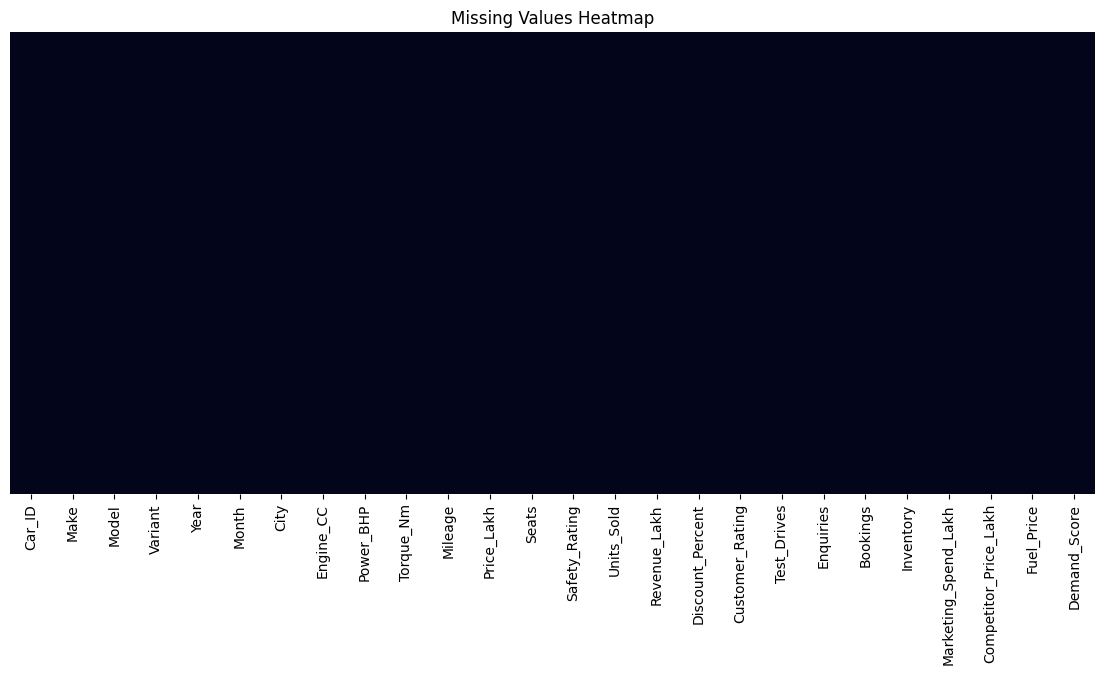

In [14]:
plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values Heatmap")
plt.show()

In [15]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1000, 26)


In [16]:
clean_df = df.copy()

In [17]:
city_sales = (
    clean_df
    .groupby('City')['Units_Sold']
    .sum()
    .sort_values(ascending=False)
)

print(city_sales)


City
Mumbai        58116
Chennai       57393
Nagpur        56689
Bengaluru     55715
Coimbatore    55707
Hyderabad     54288
Delhi         51480
Lucknow       50563
Jaipur        45547
Indore        45479
Chandigarh    44868
Kolkata       43783
Kochi         40674
Surat         38935
Ahmedabad     37552
Pune          36777
Name: Units_Sold, dtype: int64


Model
XUV700             15501
Eeco               15329
Brezza             15130
Kodiaq             15005
Creta              14806
Ioniq 5            14408
C5 Aircross        12883
Seltos             12850
Thar               12700
XUV300, XUV 3X0    12367
Name: Units_Sold, dtype: int64


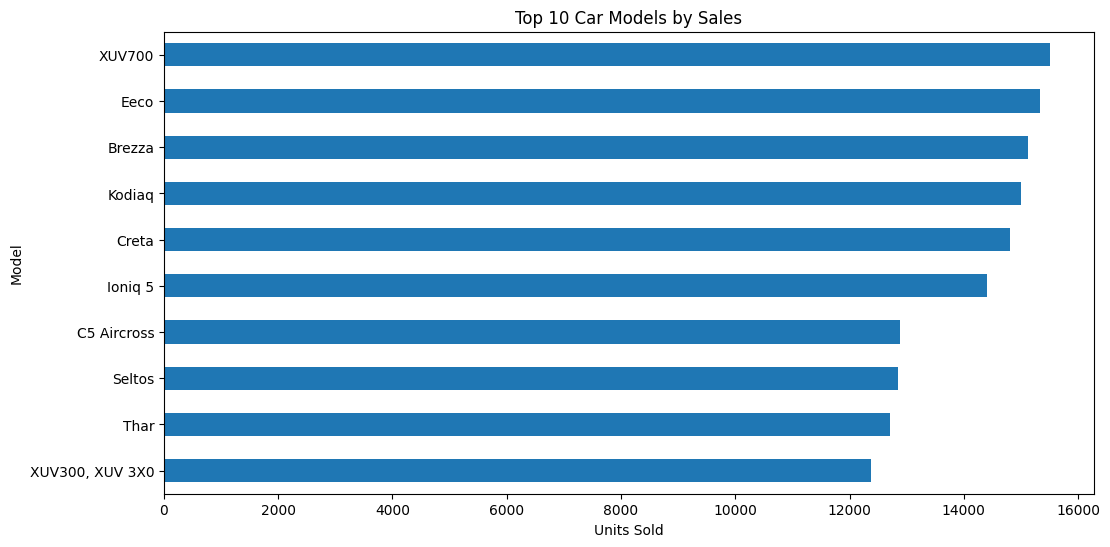

In [18]:
top_models = (
    clean_df
    .groupby('Model')['Units_Sold']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_models)


plt.figure(figsize=(12, 6))

top_models.sort_values().plot(kind='barh')

plt.title("Top 10 Car Models by Sales")
plt.xlabel("Units Sold")

plt.show()

In [19]:
rating_by_make = (
    clean_df
    .groupby('Make')['Customer_Rating']
    .mean()
    .sort_values(ascending=False)
)

print(rating_by_make)

Make
Jeep          3.928571
Nissan        3.840909
MG            3.756667
Kia           3.695161
Toyota        3.695050
Tata          3.691489
Skoda         3.689130
Honda         3.688571
Hyundai       3.686179
Renault       3.682051
Citroen       3.679661
Mahindra      3.677778
Volkswagen    3.657692
Maruti        3.620398
Name: Customer_Rating, dtype: float64


In [20]:

# : DATA CLEANING

# Keep a copy of the original data
df_clean = df.copy()

# Remove duplicate rows
df_clean = df_clean.drop_duplicates()

# Clean column names
df_clean.columns = (
    df_clean.columns.str.strip()
    .str.replace(" ", "_")
)

# Remove extra spaces from text columns
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Replace blank text values with missing values
df_clean[text_cols] = df_clean[text_cols].replace(
    r"^\s*$", np.nan, regex=True
)

# Convert numeric-looking columns to numeric values
# Exclude identifiers and categorical fields
categorical_cols = [
    "Car_ID", "Make", "Model", "Variant", "Month", "City"
]

for col in df_clean.columns:
    if col not in categorical_cols:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

# Fill missing numerical values with the median
numeric_cols = df_clean.select_dtypes(
    include=np.number
).columns

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

# Fill missing categorical values with the mode
for col in text_cols:
    if df_clean[col].isna().any():
        mode_values = df_clean[col].mode()
        if not mode_values.empty:
            df_clean[col] = df_clean[col].fillna(
                mode_values.iloc[0]
            )

print("Cleaning completed.")
print("Cleaned dataset shape:", df_clean.shape)
print("\nRemaining missing values:")
print(df_clean.isnull().sum())


Cleaning completed.
Cleaned dataset shape: (1000, 26)

Remaining missing values:
Car_ID                   0
Make                     0
Model                    0
Variant                  0
Year                     0
Month                    0
City                     0
Engine_CC                0
Power_BHP                0
Torque_Nm                0
Mileage                  0
Price_Lakh               0
Seats                    0
Safety_Rating            0
Units_Sold               0
Revenue_Lakh             0
Discount_Percent         0
Customer_Rating          0
Test_Drives              0
Enquiries                0
Bookings                 0
Inventory                0
Marketing_Spend_Lakh     0
Competitor_Price_Lakh    0
Fuel_Price               0
Demand_Score             0
dtype: int64


In [21]:

#  PREDICT DEMAND SCORE USING RANDOM FOREST

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Target variable
target = "Demand_Score"

# Remove target and unique ID from input features
X = df_clean.drop(columns=[target, "Car_ID"])
y = df_clean[target]

# Identify categorical and numerical columns
categorical = X.select_dtypes(
    include=["object", "string"]
).columns.tolist()

numerical = X.select_dtypes(
    include=np.number
).columns.tolist()

# Prepare preprocessing
preprocessor = ColumnTransformer([
    ("numeric", SimpleImputer(strategy="median"), numerical),
    ("categorical", make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(handle_unknown="ignore")
    ), categorical)
])

# Create model pipeline
model = make_pipeline(
    preprocessor,
    RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
)

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train and evaluate
model.fit(X_train, y_train)
predictions = model.predict(X_test)

print("Mean Absolute Error:",
      round(mean_absolute_error(y_test, predictions), 3))

print("R-squared Score:",
      round(r2_score(y_test, predictions), 3))


Mean Absolute Error: 5.325
R-squared Score: 0.856


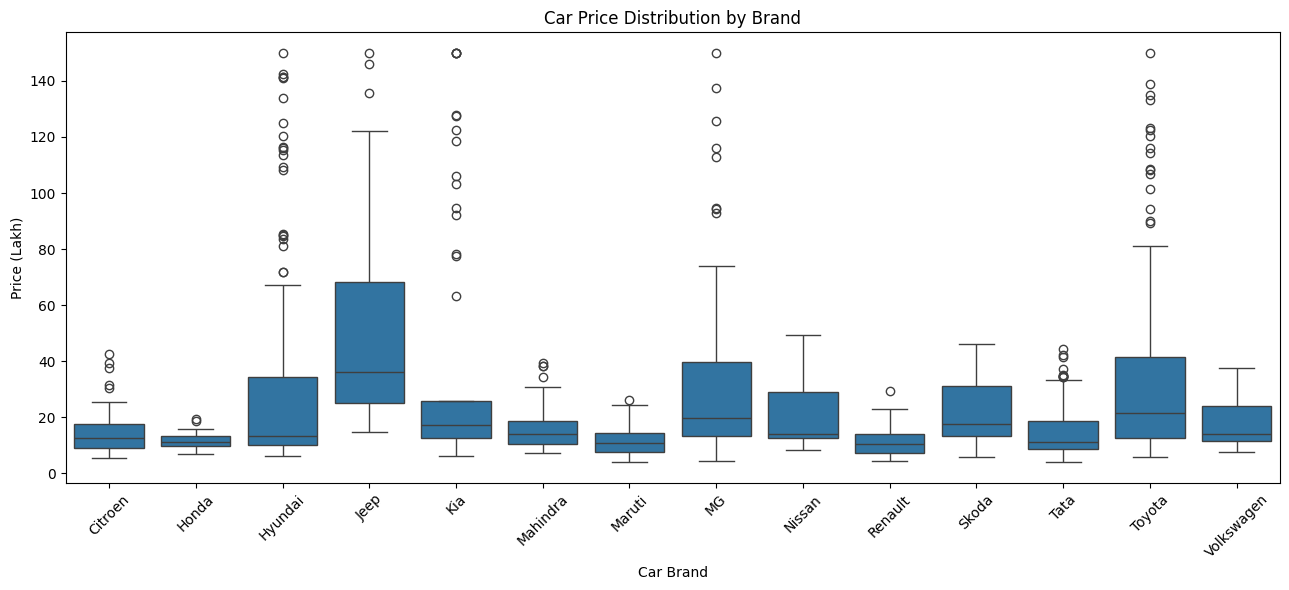

In [23]:

#  PRICE DISTRIBUTION BY BRAND

plt.figure(figsize=(13, 6))

sns.boxplot(
    data=df_clean,
    x="Make",
    y="Price_Lakh"
)

plt.title("Car Price Distribution by Brand")
plt.xlabel("Car Brand")
plt.ylabel("Price (Lakh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


,Total_Units_Sold,Total_Revenue,Average_Price,Average_Mileage,Average_Rating
Make,,,,,
Hyundai,101727,2503816.97,33.41,16.40,3.69
Toyota,77226,2181162.39,38.67,14.80,3.70
Maruti,159367,1505635.11,11.38,18.61,3.62
Kia,42802,1477178.90,39.13,15.04,3.70
Mahindra,83601,1179615.57,15.67,16.43,3.68
Tata,82708,1063448.02,15.09,18.35,3.69
MG,38090,1032905.24,35.66,15.48,3.76
Jeep,28024,1017359.98,51.07,13.22,3.93
Skoda,38086,680197.36,21.72,16.27,3.69


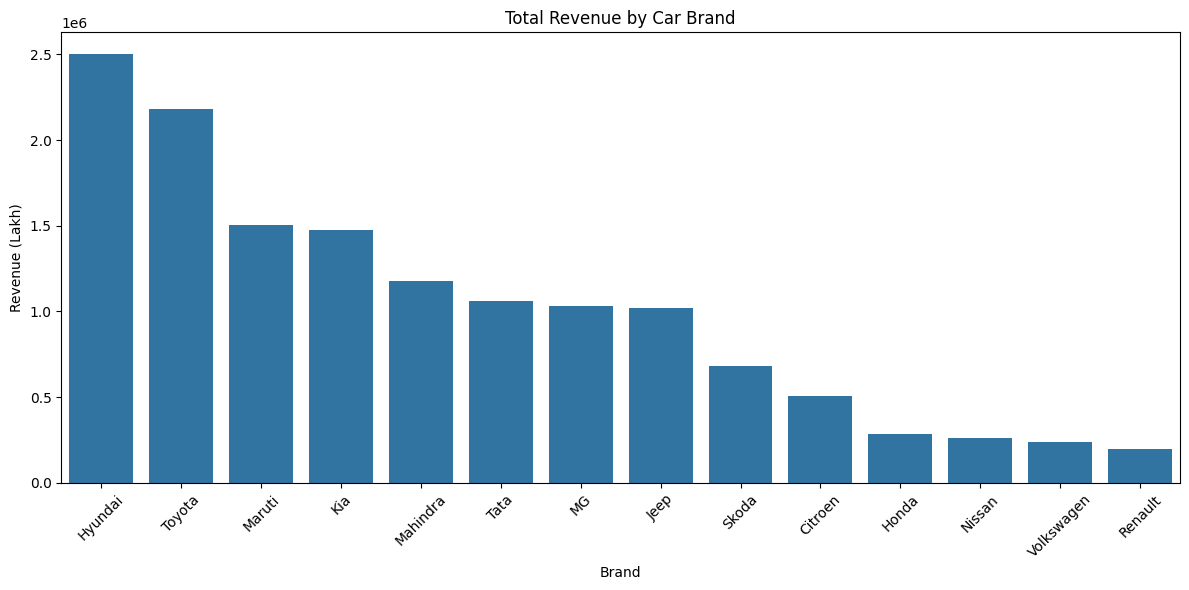

In [22]:

# : GROUPING AND AGGREGATION

brand_summary = df_clean.groupby("Make").agg(
    Total_Units_Sold=("Units_Sold", "sum"),
    Total_Revenue=("Revenue_Lakh", "sum"),
    Average_Price=("Price_Lakh", "mean"),
    Average_Mileage=("Mileage", "mean"),
    Average_Rating=("Customer_Rating", "mean")
).round(2)

brand_summary = brand_summary.sort_values(
    "Total_Revenue", ascending=False
)

display(brand_summary)

# Plot revenue by brand
plt.figure(figsize=(12, 6))

sns.barplot(
    x=brand_summary.index,
    y=brand_summary["Total_Revenue"]
)

plt.title("Total Revenue by Car Brand")
plt.xlabel("Brand")
plt.ylabel("Revenue (Lakh)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


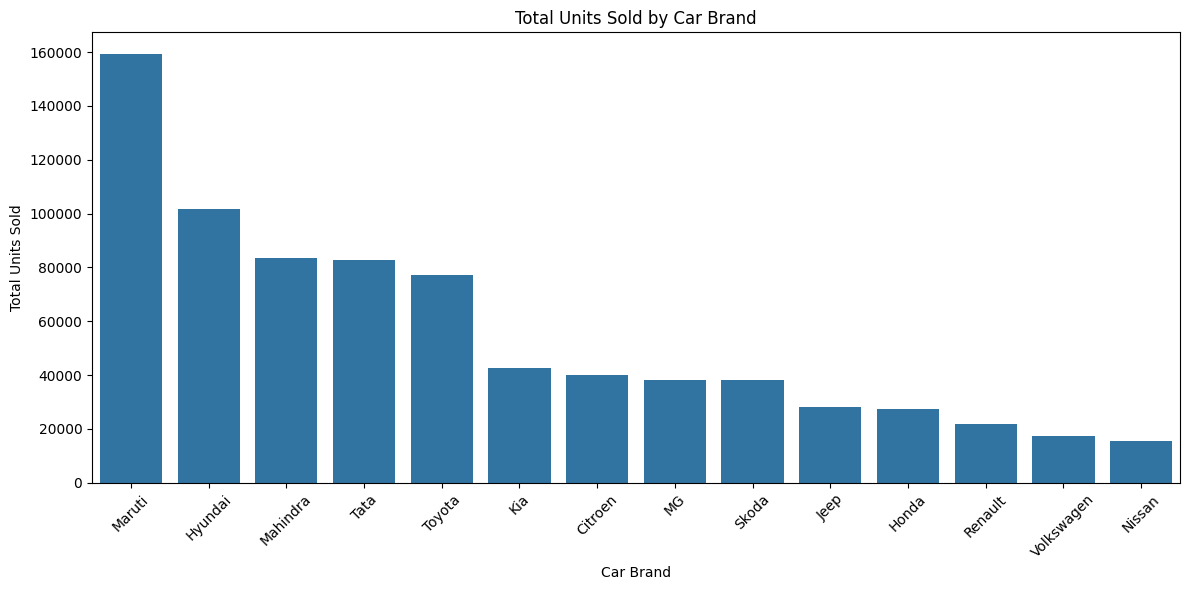

,Total_Units_Sold
Make,
Maruti,159367
Hyundai,101727
Mahindra,83601
Tata,82708
Toyota,77226
Kia,42802
Citroen,39932
MG,38090
Skoda,38086


In [24]:

#  SALES BY CAR BRAND

brand_sales = (
    df_clean.groupby("Make")["Units_Sold"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))
sns.barplot(
    x=brand_sales.index,
    y=brand_sales.values
)

plt.title("Total Units Sold by Car Brand")
plt.xlabel("Car Brand")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(brand_sales.to_frame("Total_Units_Sold"))
